# Fetal Health Active Learning: corrected baseline and proposed improvements

**Base paper:** Bhardwaj et al., *A Novel Active Learning Technique for Fetal Health Classification Based on
XGBoost Classifier*, IEEE Access 13 (2025). The code is from the authors' repository `niyg7/fetal-health-dataset`.

### Part A: corrections to the base implementation
1. **Test-set leakage.** The original appended the whole unlabeled pool to the test set every iteration, so about 22% of
   test rows were copies of training samples. The reported 99.38% comes from this. Here the test set is a fixed held-out half.
2. **Diversity on row indices.** The original computed `euclidean(i, j)` between row *positions*. Here distance uses feature vectors, as the paper describes.
3. **Hyperparameters swapped.** Here XGBoost defaults are used during the AL loop and tuned values for the final model (paper Sec. III-C).
4. **Same initial set in every run.** Here each run draws a random initial set and split from its seed.

### Part B: proposed improvements (contributions)
| | Improvement | What it targets |
|---|---|---|
| C1 | **Leaf-embedding diversity.** Distance between samples = fraction of XGBoost trees in which they fall into different leaves (Hamming distance on `model.apply`) | Label efficiency: diversity measured in the classifier's own learned space instead of raw, unscaled features |
| C2 | **Class-balanced final model.** Inverse-frequency sample weights when training the final XGBoost | Recall of the minority Suspect and Pathological classes |
| C3 | **Stabilizing-predictions stopping rule.** Stop when Cohen's κ between consecutive models' predictions on the unlabeled pool is ≥ 0.998 for 5 iterations in a row | Fewer expert labels; replaces the fixed 420-sample budget |
| C4 | *(optional, recall-focused)* **Self-training.** Pseudo-label pool samples the final model predicts with ≥ 0.99 confidence (weight 0.5) and retrain | Suspect recall, at a small accuracy cost |

The stopping rule uses only model predictions on unlabeled data, so it needs no extra labels. Everything is evaluated on the same held-out test sets with paired Wilcoxon tests across runs.

In [1]:
import time, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from xgboost import XGBClassifier
from scipy.spatial.distance import cdist
from scipy.stats import wilcoxon
from joblib import Parallel, delayed
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, f1_score, recall_score, precision_score, balanced_accuracy_score,
                             cohen_kappa_score, classification_report, confusion_matrix)

## Configuration

In [2]:
DATA_PATH   = 'fetal_health.csv'
N_RUNS      = 30          # independent runs (seeds 0..N_RUNS-1)
N_JOBS      = -1          # runs in parallel across CPU cores
M_INIT      = 30          # initial labeled samples
N_UNCERTAIN = 20          # n: uncertain candidates
K_DIVERSE   = 5           # k: samples queried per iteration
N_ITER      = 78          # 30 + 78*5 = 420 labels (paper's budget)

TUNED_PARAMS = dict(n_estimators=200, learning_rate=0.05, max_depth=5, min_child_weight=1,
                    gamma=0, subsample=1, colsample_bytree=0.5)   # paper's grid-search optimum
STOP_KAPPA, STOP_WINDOW = 0.998, 5                                  # C3
SELF_TRAIN_CONF, PSEUDO_WEIGHT = 0.99, 0.5                          # C4
SEEDS = list(range(N_RUNS))
CLASS_NAMES = ['Normal', 'Suspect', 'Pathological']

## Data and splits

In [3]:
df = pd.read_csv(DATA_PATH)
y_all = pd.Series(LabelEncoder().fit_transform(df['fetal_health']), index=df.index)   # 1,2,3 -> 0,1,2
X_all = df.drop(columns=['fetal_health'])
print(df.shape, dict(zip(CLASS_NAMES, np.bincount(y_all))))

def make_split(seed):
    """30 random initial labels; the rest split 50/50 into unlabeled pool and held-out test set."""
    X_init, X_rest, y_init, y_rest = train_test_split(X_all, y_all, train_size=M_INIT, random_state=seed)
    X_pool, X_test, y_pool, y_test = train_test_split(X_rest, y_rest, train_size=0.5, random_state=seed)
    assert not (set(X_init.index) | set(X_pool.index)) & set(X_test.index)
    return X_init, y_init, X_pool, y_pool, X_test, y_test

s = make_split(0); print('initial', len(s[0]), '| pool', len(s[2]), '| test', len(s[4]))

(2126, 22) {'Normal': np.int64(1655), 'Suspect': np.int64(295), 'Pathological': np.int64(176)}
initial 30 | pool 1048 | test 1048


## Building blocks

* **Uncertainty (paper):** margin = top-1 minus top-2 class probability; the `n` smallest margins are kept.
* **Diversity (Algorithm 1):** start from the most uncertain candidate, then greedily add the candidate with the largest summed
  distance to the selected set. `'raw'` = Euclidean on raw features (paper); `'leaf'` = Hamming distance between XGBoost
  leaf indices (C1).

In [4]:
def xgb(params, seed):
    return XGBClassifier(objective='multi:softprob', num_class=3, random_state=seed, n_jobs=1, **params)

def predict(model, X):
    return np.argmax(model.predict_proba(X), axis=1)

def margin(model, X):
    p = np.sort(model.predict_proba(X), axis=1)
    return p[:, -1] - p[:, -2]

def embed(model, X, kind):
    if kind == 'raw':  return X.values, 'euclidean'                    # paper
    if kind == 'leaf': return model.apply(X).astype(float), 'hamming'  # C1: leaf embedding
    raise ValueError(kind)

def greedy_diverse(F, metric, candidates, k):
    selected, remaining = [candidates[0]], list(candidates[1:])
    while len(selected) < k and remaining:
        d = cdist(F[remaining], F[selected], metric=metric).sum(axis=1)
        selected.append(remaining.pop(int(np.argmax(d))))
    return selected

def query(strategy, model, X_pool, rng, div):
    if strategy == 'random':
        return list(rng.choice(len(X_pool), K_DIVERSE, replace=False))
    m = margin(model, X_pool)
    if strategy == 'certain':     return list(np.argsort(m)[-K_DIVERSE:])
    if strategy == 'uncertainty': return list(np.argsort(m)[:K_DIVERSE])
    top = list(np.argsort(m)[:N_UNCERTAIN])                             # uncertainty + diversity
    F, metric = embed(model, X_pool, div)
    return greedy_diverse(F, metric, top, K_DIVERSE)

def class_weights(y, on):
    return compute_sample_weight('balanced', y) if on else None

def metrics(y_true, y_pred):
    r = recall_score(y_true, y_pred, average=None, labels=[0, 1, 2])
    return dict(accuracy=accuracy_score(y_true, y_pred) * 100,
                macro_F1=f1_score(y_true, y_pred, average='macro') * 100,
                balanced_acc=balanced_accuracy_score(y_true, y_pred) * 100,
                recall_Normal=r[0] * 100, recall_Suspect=r[1] * 100, recall_Pathological=r[2] * 100)

## Active learning run

In [5]:
def run_al(seed, strategy='al', div='raw', balanced_final=False, stop=False, self_train=False):
    rng = np.random.default_rng(seed)
    X_tr, y_tr, X_pool, y_pool, X_te, y_te = make_split(seed)
    X_stop = X_pool.copy()                    # unlabeled set the stopping rule watches (labels never used)
    prev, kappas, curve, sizes = None, [], [], []
    for it in range(N_ITER):
        model = xgb({}, seed).fit(X_tr, y_tr)                    # defaults inside the loop (paper)
        curve.append(accuracy_score(y_te, predict(model, X_te)) * 100); sizes.append(len(X_tr))
        cur = predict(model, X_stop)
        if prev is not None: kappas.append(cohen_kappa_score(prev, cur))
        prev = cur
        if stop and len(kappas) >= STOP_WINDOW and min(kappas[-STOP_WINDOW:]) >= STOP_KAPPA:
            break                                                # C3: predictions have stabilized
        sel = query(strategy, model, X_pool, rng, div)
        X_tr = pd.concat([X_tr, X_pool.iloc[sel]]); y_tr = pd.concat([y_tr, y_pool.iloc[sel]])
        X_pool = X_pool.drop(X_pool.index[sel]);    y_pool = y_pool.drop(y_pool.index[sel])
    assert not set(X_tr.index) & set(X_te.index)

    final = xgb(TUNED_PARAMS, seed).fit(X_tr, y_tr, sample_weight=class_weights(y_tr, balanced_final))  # C2
    if self_train:                                                                                       # C4
        P = final.predict_proba(X_pool); keep = P.max(axis=1) >= SELF_TRAIN_CONF
        X_st = pd.concat([X_tr, X_pool[keep]])
        y_st = pd.concat([y_tr, pd.Series(P[keep].argmax(axis=1), index=X_pool.index[keep])])
        w = np.r_[np.ones(len(X_tr)), np.full(keep.sum(), PSEUDO_WEIGHT)]
        if balanced_final: w = w * compute_sample_weight('balanced', y_st)
        final = xgb(TUNED_PARAMS, seed).fit(X_st, y_st, sample_weight=w)
    y_pred = predict(final, X_te)
    out = metrics(y_te, y_pred)
    out.update(labels_used=len(X_tr), curve=curve, sizes=sizes, y_test=y_te.values, y_pred=y_pred)
    return out

## Experiments

In [6]:
EXPERIMENTS = {
    'Random sampling':                     dict(strategy='random'),
    'Certain sampling':                    dict(strategy='certain'),
    'Uncertainty only':                    dict(strategy='uncertainty'),
    'Base paper (corrected)':              dict(div='raw'),
    'C1: leaf diversity':                  dict(div='leaf'),
    'C2: class-balanced final':            dict(div='raw', balanced_final=True),
    'Proposed (C1+C2+C3)':                 dict(div='leaf', balanced_final=True, stop=True),
    'Proposed + self-training (C1-C4)':    dict(div='leaf', balanced_final=True, stop=True, self_train=True),
}
results = {}
for name, cfg in EXPERIMENTS.items():
    t = time.time()
    results[name] = Parallel(n_jobs=N_JOBS)(delayed(run_al)(s, **cfg) for s in SEEDS)
    a = [r['accuracy'] for r in results[name]]
    print(f'{name:36s} acc {np.mean(a):.2f} ± {np.std(a):.2f}   ({time.time() - t:.0f}s)')

Random sampling                      acc 91.94 ± 1.12   (50s)


Certain sampling                     acc 84.04 ± 2.49   (40s)


Uncertainty only                     acc 94.58 ± 0.50   (77s)


Base paper (corrected)               acc 94.55 ± 0.56   (78s)


C1: leaf diversity                   acc 94.56 ± 0.57   (89s)


C2: class-balanced final             acc 94.55 ± 0.59   (80s)


Proposed (C1+C2+C3)                  acc 94.48 ± 0.57   (72s)


Proposed + self-training (C1-C4)     acc 94.18 ± 0.61   (74s)


### Reference: supervised XGBoost trained on the full pool (≈1078 labels), same test sets

In [7]:
def run_full(seed):
    X_i, y_i, X_p, y_p, X_te, y_te = make_split(seed)
    m = xgb(TUNED_PARAMS, seed).fit(pd.concat([X_i, X_p]), pd.concat([y_i, y_p]))
    out = metrics(y_te, predict(m, X_te)); out['labels_used'] = len(X_i) + len(X_p); return out
full = Parallel(n_jobs=N_JOBS)(delayed(run_full)(s) for s in SEEDS)
print('full pool accuracy: %.2f' % np.mean([r['accuracy'] for r in full]))

full pool accuracy: 94.40


## Results table (mean over runs)

In [8]:
METRICS = ['accuracy', 'macro_F1', 'balanced_acc', 'recall_Normal', 'recall_Suspect', 'recall_Pathological', 'labels_used']
def table(res):
    return pd.DataFrame([r for r in res])[METRICS].mean()
summary = pd.DataFrame({name: table(res) for name, res in results.items()}).T
summary.loc['Supervised, full pool'] = pd.DataFrame(full)[METRICS].mean()
summary.round(2)

,accuracy,macro_F1,balanced_acc,recall_Normal,recall_Suspect,recall_Pathological,labels_used
Random sampling,91.94,84.64,81.93,97.28,71.68,76.82,420.0
Certain sampling,84.04,61.37,58.32,96.55,45.80,32.62,420.0
Uncertainty only,94.58,90.49,89.18,97.80,79.23,90.53,420.0
Base paper (corrected),94.55,90.45,89.11,97.80,79.02,90.51,420.0
C1: leaf diversity,94.56,90.46,89.12,97.79,79.18,90.38,420.0
C2: class-balanced final,94.55,90.61,90.30,97.13,81.83,91.94,420.0
Proposed (C1+C2+C3),94.48,90.48,90.12,97.11,81.41,91.84,355.5
Proposed + self-training (C1-C4),94.18,90.25,90.96,96.13,84.50,92.24,355.5
"Supervised, full pool",94.40,90.17,88.55,97.88,77.80,89.96,1078.0


## Paired significance vs. the corrected base method (Wilcoxon signed-rank, same seeds)

In [9]:
base = pd.DataFrame(results['Base paper (corrected)'])
rows = {}
for name in ['C1: leaf diversity', 'C2: class-balanced final', 'Proposed (C1+C2+C3)', 'Proposed + self-training (C1-C4)']:
    cur = pd.DataFrame(results[name]); row = {}
    for m in METRICS[:-1]:
        d = cur[m] - base[m]
        p = wilcoxon(d).pvalue if np.any(d != 0) else 1.0
        row[m] = f'{d.mean():+.2f} (p={p:.3f})'
    row['labels_used'] = f"{cur['labels_used'].mean():.0f} vs {base['labels_used'].mean():.0f}"
    rows[name] = row
pd.DataFrame(rows).T

,accuracy,macro_F1,balanced_acc,recall_Normal,recall_Suspect,recall_Pathological,labels_used
C1: leaf diversity,+0.01 (p=0.789),+0.01 (p=0.903),+0.01 (p=0.792),-0.01 (p=0.882),+0.16 (p=0.518),-0.14 (p=0.268),420 vs 420
C2: class-balanced final,+0.00 (p=0.802),+0.16 (p=0.114),+1.19 (p=0.000),-0.67 (p=0.000),+2.81 (p=0.000),+1.42 (p=0.000),420 vs 420
Proposed (C1+C2+C3),-0.08 (p=0.373),+0.03 (p=0.871),+1.01 (p=0.000),-0.69 (p=0.000),+2.39 (p=0.000),+1.33 (p=0.000),356 vs 420
Proposed + self-training (C1-C4),-0.38 (p=0.003),-0.20 (p=0.213),+1.85 (p=0.000),-1.68 (p=0.000),+5.48 (p=0.000),+1.73 (p=0.000),356 vs 420


## Learning curves

These are held-out accuracies of the loop model after each query. The proposed method's runs stop at different points,
so its curve is cut where the first run stops; C1 alone shows the full 420-label curve.

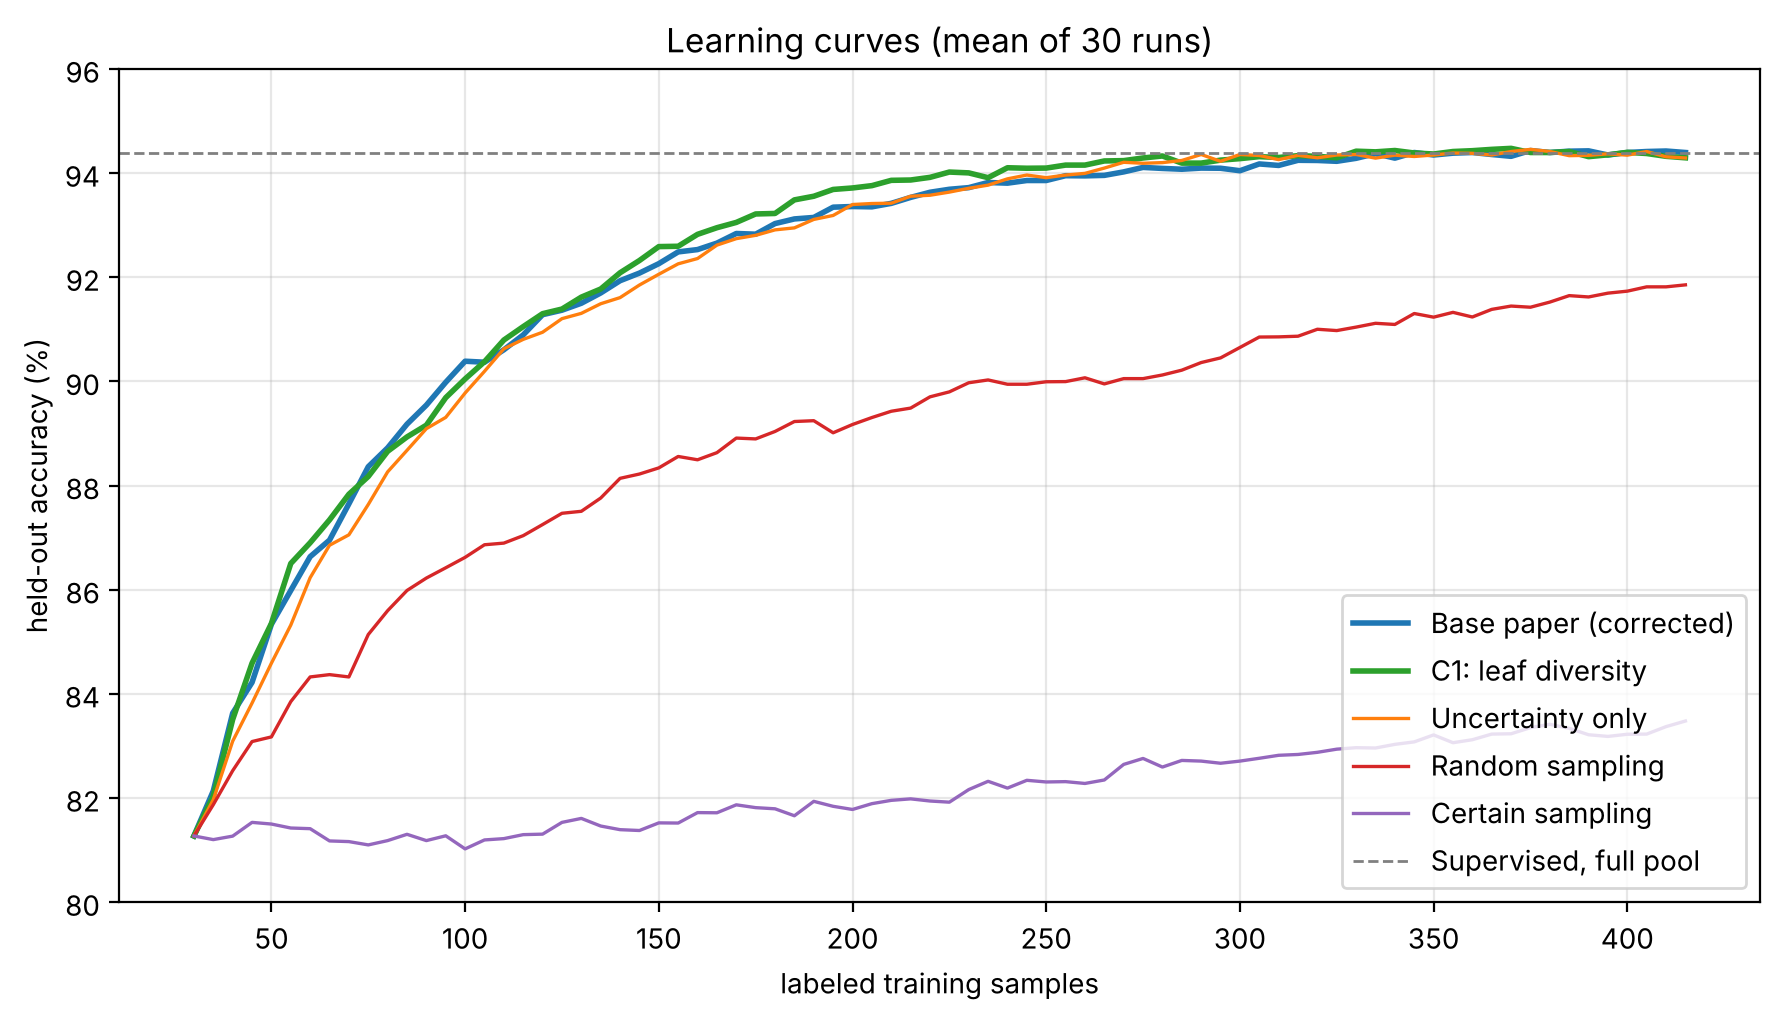

base: first label count with mean accuracy >= 94%: 270
leaf: first label count with mean accuracy >= 94%: 225


,labels,base,leaf,diff,p
0,100,90.388,90.048,-0.340,0.280
1,150,92.261,92.589,0.328,0.225
2,200,93.359,93.715,0.356,0.064
3,250,93.858,94.097,0.239,0.041
4,300,94.046,94.278,0.232,0.018
5,350,94.348,94.367,0.019,0.853


In [10]:
def mean_curve(res):
    L = min(len(r['curve']) for r in res)
    return np.array(res[0]['sizes'][:L]), np.mean([r['curve'][:L] for r in res], axis=0)

fig, ax = plt.subplots(figsize=(9, 5.2))
style = {'Base paper (corrected)': dict(color='tab:blue', lw=2),
         'C1: leaf diversity': dict(color='tab:green', lw=2),
         'Uncertainty only': dict(color='tab:orange', lw=1.2),
         'Random sampling': dict(color='tab:red', lw=1.2),
         'Certain sampling': dict(color='tab:purple', lw=1.2)}
for name, st in style.items():
    x, c = mean_curve(results[name]); ax.plot(x, c, label=name, **st)
ax.axhline(np.mean([r['accuracy'] for r in full]), color='grey', ls='--', lw=1, label='Supervised, full pool')
ax.set_xlabel('labeled training samples'); ax.set_ylabel('held-out accuracy (%)'); ax.set_ylim(80, 96)
ax.set_title(f'Learning curves (mean of {N_RUNS} runs)'); ax.grid(alpha=0.3); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

S = results['Base paper (corrected)'][0]['sizes']
B = np.array([r['curve'] for r in results['Base paper (corrected)']])
L = np.array([r['curve'] for r in results['C1: leaf diversity']])
rows = []
for n in (100, 150, 200, 250, 300, 350):
    i = S.index(n); d = L[:, i] - B[:, i]
    rows.append(dict(labels=n, base=B[:, i].mean(), leaf=L[:, i].mean(), diff=d.mean(), p=wilcoxon(d).pvalue))
for name, C in (('base', B), ('leaf', L)):
    m = C[:, :len(S)].mean(axis=0)
    print(f'{name}: first label count with mean accuracy >= 94%:', S[int(np.argmax(m >= 94))])
pd.DataFrame(rows).round(3)

## Stopping rule: labels used per run

                     count   mean   std    min    25%    50%    75%    max
Proposed (C1+C2+C3)   30.0  355.5  42.6  290.0  321.2  345.0  398.8  420.0


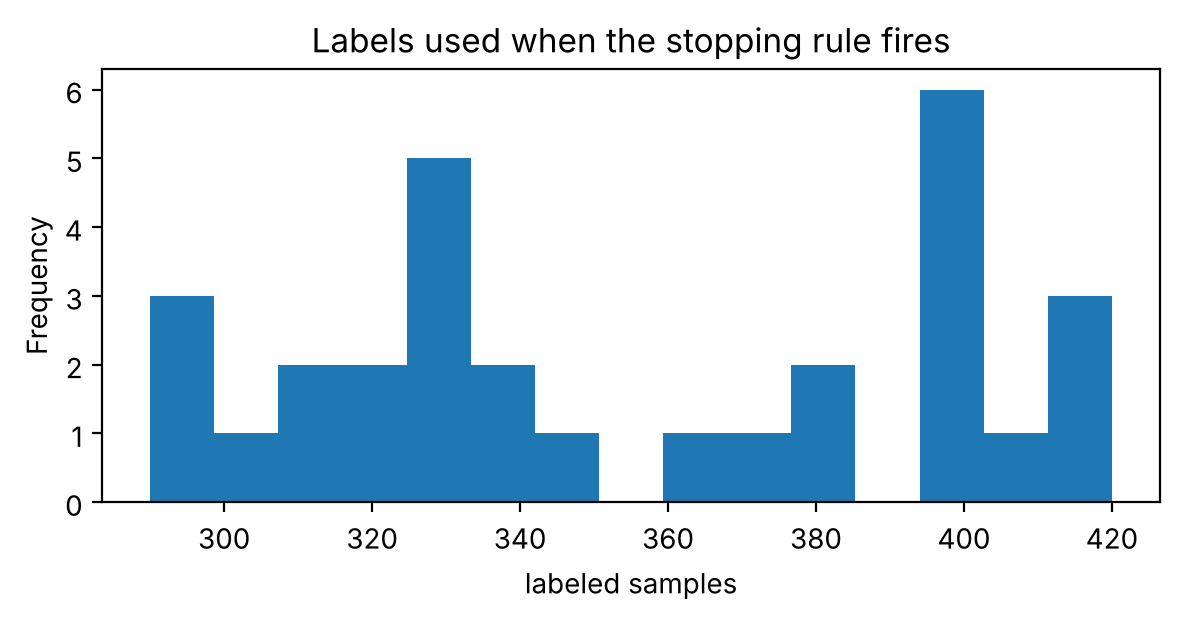

In [11]:
lab = pd.DataFrame({'Proposed (C1+C2+C3)': [r['labels_used'] for r in results['Proposed (C1+C2+C3)']]})
print(lab.describe().round(1).T)
lab.plot.hist(bins=15, legend=False, figsize=(6, 3.2), title='Labels used when the stopping rule fires')
plt.xlabel('labeled samples'); plt.tight_layout(); plt.show()

## Per-class report and confusion matrices (pooled over runs)

===== Base paper (corrected)
              precision    recall  f1-score   support

      Normal     0.9599    0.9780    0.9689     24388
     Suspect     0.8598    0.7890    0.8229      4360
Pathological     0.9402    0.9049    0.9222      2692

    accuracy                         0.9455     31440
   macro avg     0.9200    0.8906    0.9047     31440
weighted avg     0.9443    0.9455    0.9446     31440



===== Proposed (C1+C2+C3)
              precision    recall  f1-score   support

      Normal     0.9653    0.9711    0.9682     24388
     Suspect     0.8393    0.8135    0.8262      4360
Pathological     0.9228    0.9186    0.9207      2692

    accuracy                         0.9448     31440
   macro avg     0.9091    0.9011    0.9050     31440
weighted avg     0.9442    0.9448    0.9444     31440



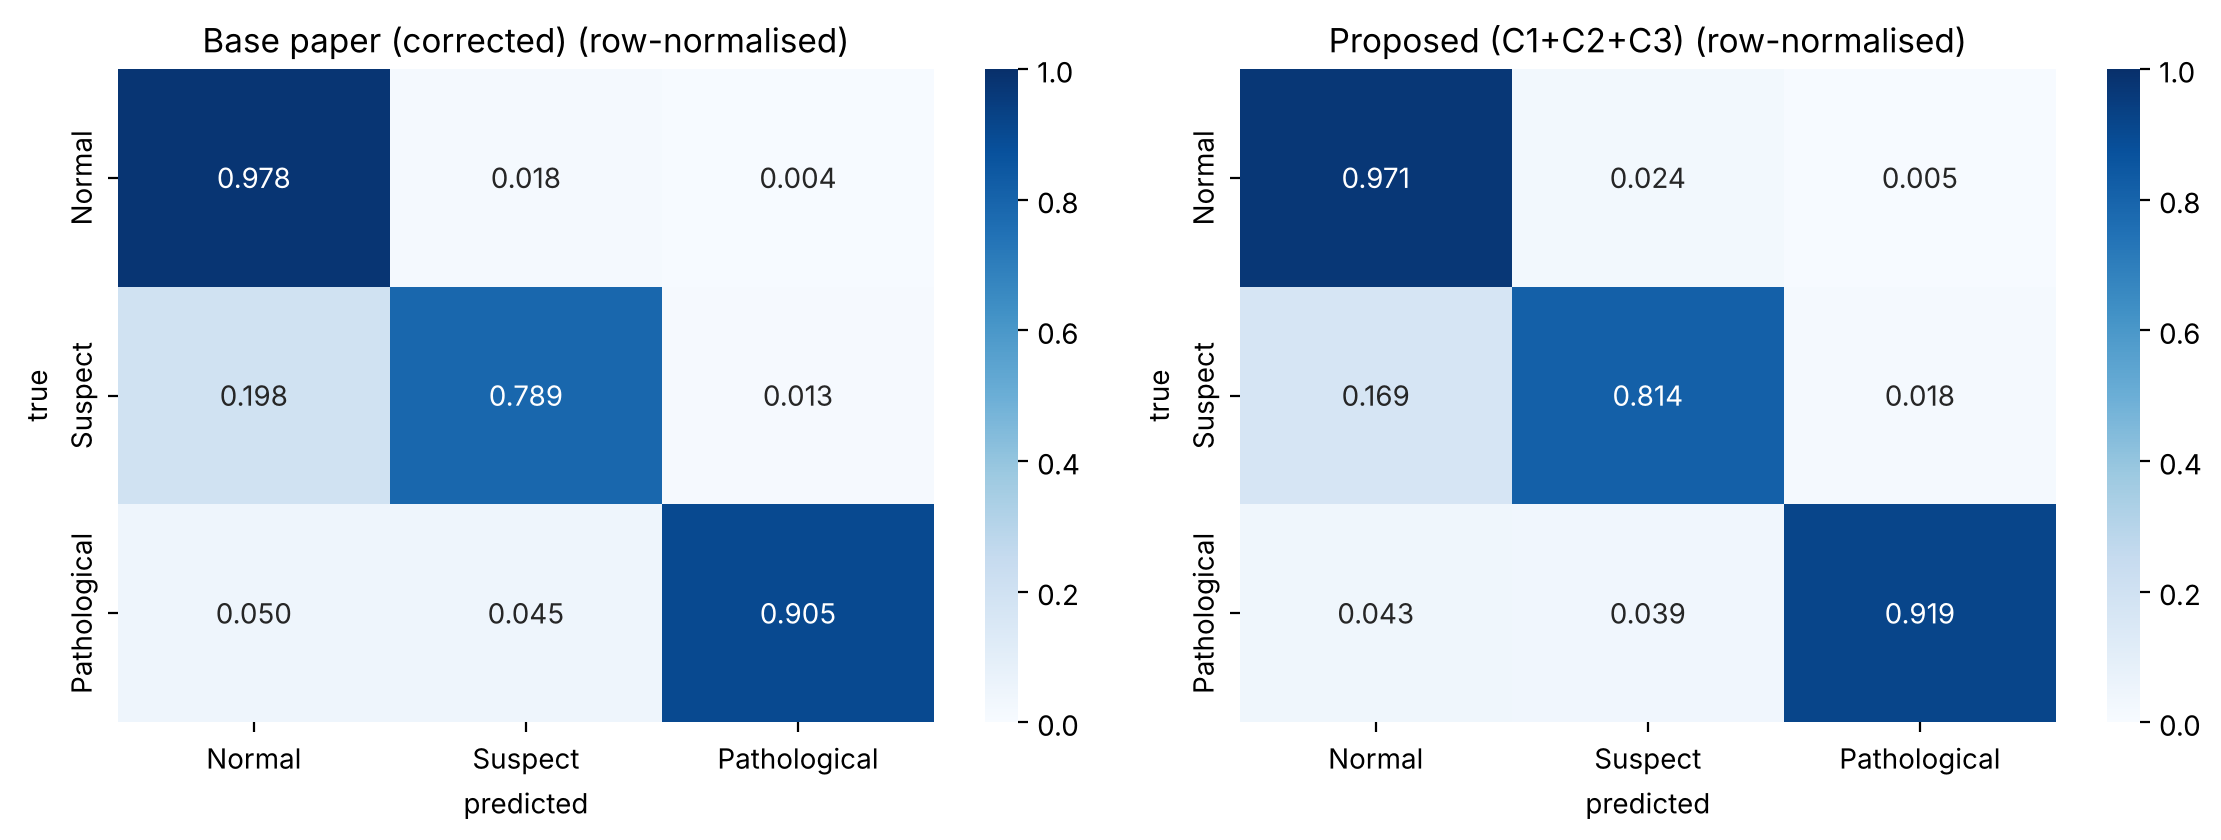

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
for ax, name in zip(axes, ['Base paper (corrected)', 'Proposed (C1+C2+C3)']):
    yt = np.concatenate([r['y_test'] for r in results[name]]); yp = np.concatenate([r['y_pred'] for r in results[name]])
    print(f'===== {name}'); print(classification_report(yt, yp, target_names=CLASS_NAMES, digits=4))
    cm = confusion_matrix(yt, yp); cmn = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cmn, annot=True, fmt='.3f', cmap='Blues', ax=ax, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, vmin=0, vmax=1)
    ax.set_title(name + ' (row-normalised)'); ax.set_xlabel('predicted'); ax.set_ylabel('true')
plt.tight_layout(); plt.show()

## Variants tried that did **not** improve on the corrected baseline

These were measured during development (10 runs, same protocol). Every one is within noise of the baseline's 94.66% accuracy:

| Variant | Accuracy | Macro F1 | Suspect recall |
|---|---|---|---|
| Diversity on standardized features | 94.73 | 90.71 | 79.0 |
| Entropy instead of margin uncertainty | 94.77 | 90.77 | 79.7 |
| Class-rarity-weighted uncertainty in the query | 94.77 | 90.77 | 79.3 |
| Class weights inside the AL loop as well | 94.50 | 90.46 | 81.7 |
| 7-model seed-bagged XGBoost final model | 94.58 | 90.39 | 78.5 |
| Self-training without class weights | 94.57 | 90.50 | 78.7 |

**Why overall accuracy doesn't move:** supervised XGBoost trained on the *entire* labeled pool (~1078 samples) reaches only
~94.5% on this test split. LightGBM, random forest and extra-trees score lower. The 420-label active learner is already at
that ceiling, so the improvements show up as minority-class recall, balanced accuracy and labels saved, not as headline accuracy.